In [1]:
import warnings

import joblib
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

                                                    EDA

In [2]:
df = pd.read_csv("house_prices.csv")

In [3]:
df.head(3)

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN


In [4]:
df.columns

Index(['Index', 'Title', 'Description', 'Amount(in rupees)',
       'Price (in rupees)', 'location', 'Carpet Area', 'Status', 'Floor',
       'Transaction', 'Furnishing', 'facing', 'overlooking', 'Society',
       'Bathroom', 'Balcony', 'Car Parking', 'Ownership', 'Super Area',
       'Dimensions', 'Plot Area'],
      dtype='object')

In [5]:
df.columns

Index(['Index', 'Title', 'Description', 'Amount(in rupees)',
       'Price (in rupees)', 'location', 'Carpet Area', 'Status', 'Floor',
       'Transaction', 'Furnishing', 'facing', 'overlooking', 'Society',
       'Bathroom', 'Balcony', 'Car Parking', 'Ownership', 'Super Area',
       'Dimensions', 'Plot Area'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  object 
 2   Description        184508 non-null  object 
 3   Amount(in rupees)  187531 non-null  object 
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  object 
 6   Carpet Area        106858 non-null  object 
 7   Status             186916 non-null  object 
 8   Floor              180454 non-null  object 
 9   Transaction        187448 non-null  object 
 10  Furnishing         184634 non-null  object 
 11  facing             117298 non-null  object 
 12  overlooking        106095 non-null  object 
 13  Society            77853 non-null   object 
 14  Bathroom           186703 non-null  object 
 15  Balcony            138596 non-null  object 
 16  Ca

In [7]:
df.isnull().sum()

Index                     0
Title                     0
Description            3023
Amount(in rupees)         0
Price (in rupees)     17665
location                  0
Carpet Area           80673
Status                  615
Floor                  7077
Transaction              83
Furnishing             2897
facing                70233
overlooking           81436
Society              109678
Bathroom                828
Balcony               48935
Car Parking          103357
Ownership             65517
Super Area           107685
Dimensions           187531
Plot Area            187531
dtype: int64

In [8]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [9]:
def missing_data(df):
    table = []
    for col in df.columns:
        table.append({
            col : f"%{(df[col].isnull().sum() / df.shape[0])*100:.2f}"
        })
    table1 = pd.DataFrame(table, columns=df.columns).stack().reset_index().drop("level_0", axis=1)
    table2 = table1.rename(columns={"level_1":"features", 0:"percentage_of_missing_data"})
    return table2

missing_data(df)    

,features,percentage_of_missing_data
0,Index,%0.00
1,Title,%0.00
2,Description,%1.61
3,Amount(in rupees),%0.00
4,Price (in rupees),%9.42
5,location,%0.00
6,Carpet Area,%43.02
7,Status,%0.33
8,Floor,%3.77
9,Transaction,%0.04


                                                EDA + FEATURE ENGINEERING

In [10]:
df = df.rename(columns={"Amount(in rupees)":"Amount", "Price (in rupees)":"Price"})

In [11]:
df.drop(["Index", "Description", "Society", "Title", "Dimensions", "Super Area", "Plot Area"], axis=1, inplace=True)

In [12]:
df["has_parking"] = df["Car Parking"].notna().astype(int)

In [13]:
df.drop(["Car Parking"], axis=1, inplace=True)

In [14]:
df.head()

,Amount,Price,location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Ownership,has_parking
0,42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,1,2,NaN,0
1,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,NaN,Freehold,1
2,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,NaN,Freehold,1
3,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,1,1,NaN,0
4,1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,NaN,Co-operative Society,1


In [15]:
df["Balcony"].unique()

array(['2', nan, '1', '3', '4', '> 10', '6', '5', '7', '10', '8', '9'],
      dtype=object)

In [16]:
df["Bathroom"].unique()

array(['1', '2', '3', '4', '6', nan, '5', '10', '9', '8', '> 10', '7'],
      dtype=object)

In [17]:
for i in ["Bathroom", "Balcony"]:
    df[i] = df[i].astype(str)
    df[i] = df[i].replace("> 10", "11")
    df[i] = df[i].replace("nan", np.nan)
    df[i] = df[i].astype(float)

In [18]:
def convert_amount(x):
    if pd.isna(x):
        return None

    x = str(x).lower().replace(",", "").strip()

    if "lac" in x:
        inr = float(x.replace("lac", "").strip()) * 100000
        return float(f"{inr / 93:.4f}")
        
    elif "cr" in x:
        inr = float(x.replace("cr", "").strip()) * 10000000
        return float(f"{inr / 93:.4f}")

    elif "call" in x:
        return None
        
    else:
        try:
            return float(x)
        except:
            return None

df["Amount"] = df["Amount"].apply(convert_amount)    

In [19]:
def convert_carpet_area(x):
    if pd.isna(x):
        return None
    x = str(x).lower()
    
    if "sqft" in x:
        m2 = float(x.replace("sqft", "").strip()) *  0.092903
        return float(f"{m2:.4f}")
        
    elif "sqyrd" in x:
        m2 = float(x.replace("sqyrd", "").strip()) * 9 *  0.092903
        return float(f"{m2:.4f}")

    else:
        try:
            return float(x)
        except:
            return None

df["Carpet Area"] = df["Carpet Area"].apply(convert_carpet_area)        

In [20]:
num_cols = df.select_dtypes(["int64", "float64"]).columns
num_cols

Index(['Amount', 'Price', 'Carpet Area', 'Bathroom', 'Balcony', 'has_parking'], dtype='object')

                                                OUTLIER

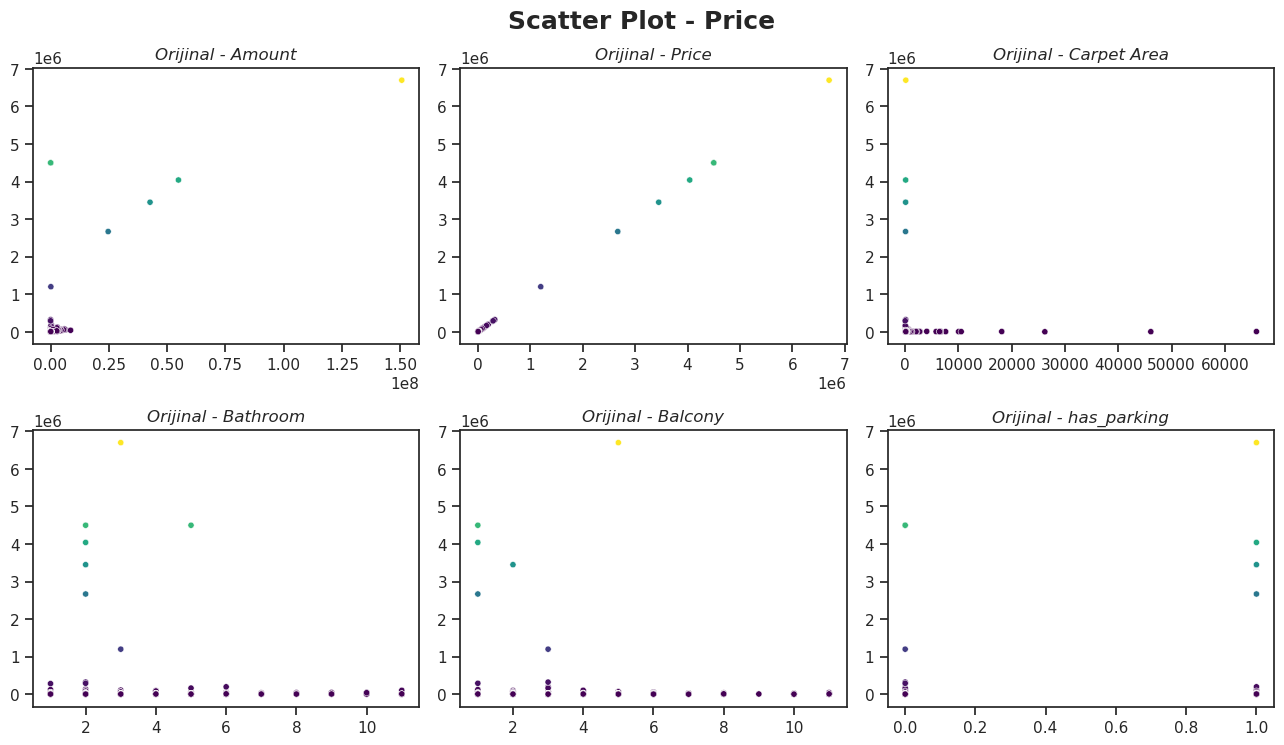

In [21]:
def scatter_plot(df, num_cols, title="Orijinal"):
    sns.set_theme(style=("ticks"))
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(13,11))
    plt.suptitle("Scatter Plot - Price", fontsize=18, fontweight="bold")

    for i, col in enumerate(num_cols):
        row = i // 3
        col_id = i % 3 
        ax = axes[row, col_id]
        sns.scatterplot(data=df, x=col, y="Price", hue="Price", palette="viridis", ax=ax, s=20, legend=False)
        ax.set_title(f"{title} - {col}", fontsize=12, style="italic")
        ax.set_xlabel("")
        ax.set_ylabel("")

    axes = axes.flatten()
    for j in range(len(num_cols), len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

scatter_plot(df, num_cols)

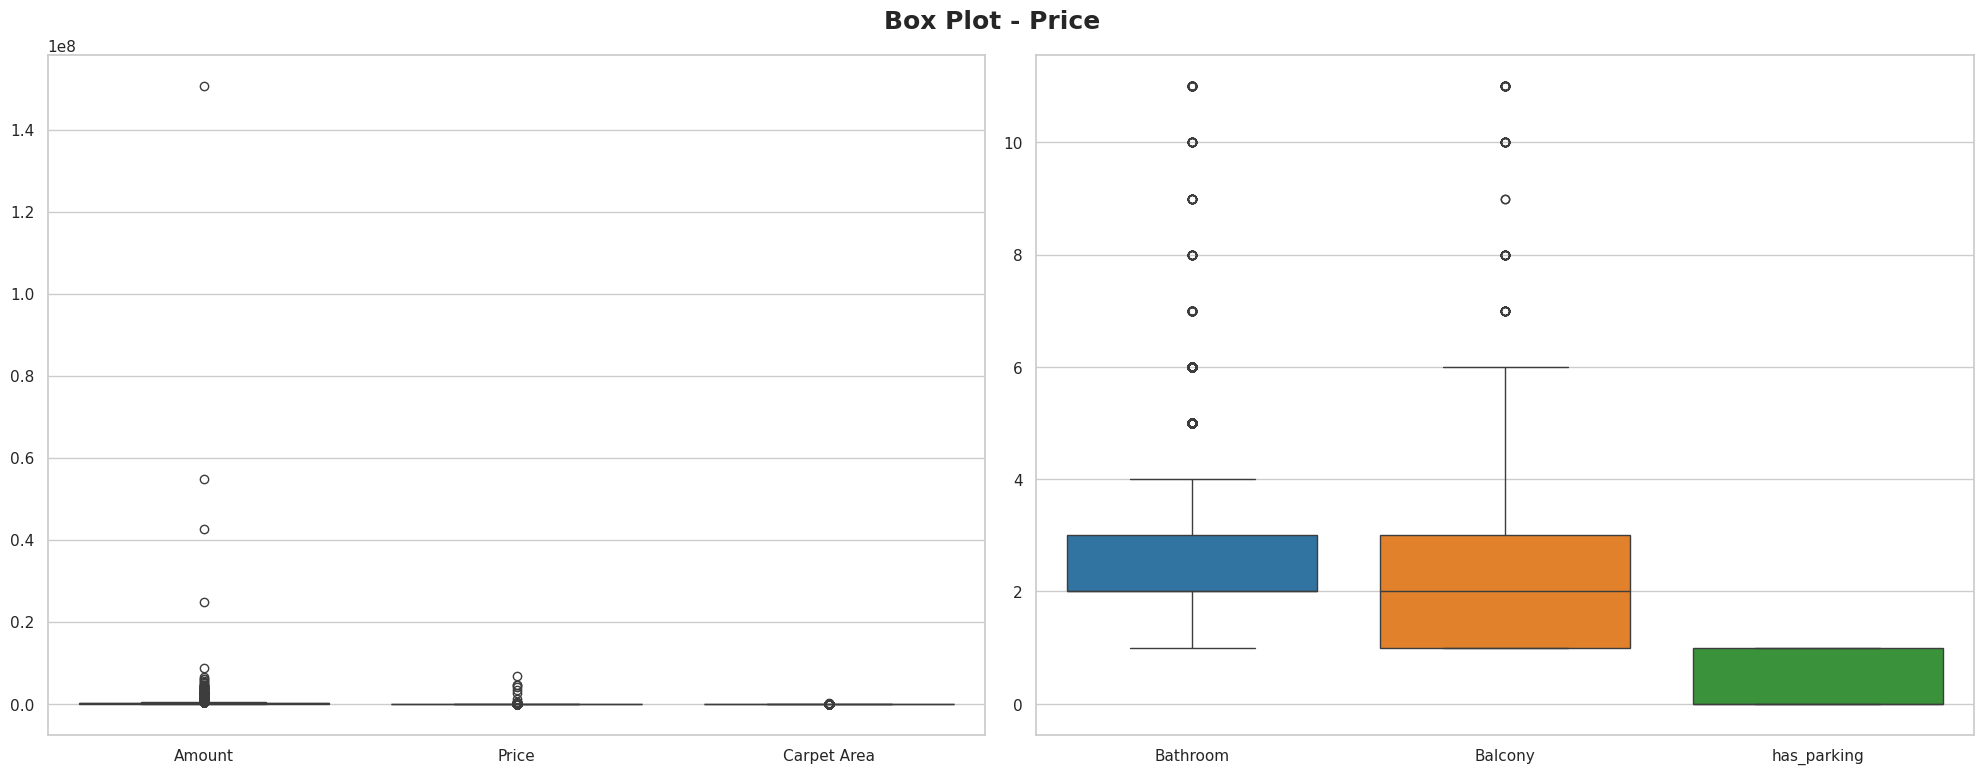

In [22]:
big_cols = ['Amount', 'Price', 'Carpet Area']
small_cols = ['Bathroom', 'Balcony', 'has_parking']
cols = [big_cols, small_cols]

def box_plot(df, num_cols):
    sns.set_theme(style=("whitegrid"), palette="tab10")
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20,15))
    plt.suptitle("Box Plot - Price", fontsize=18, fontweight="bold")
    
    for i, col in enumerate(cols):
        row = i // 2
        col_id = i % 2
        ax = axes[row, col_id]
        sns.boxplot(data=df[col], ax=ax, fill=True)
    
    axes = axes.flatten()
    for j in range(len(cols), len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

box_plot(df, num_cols)    

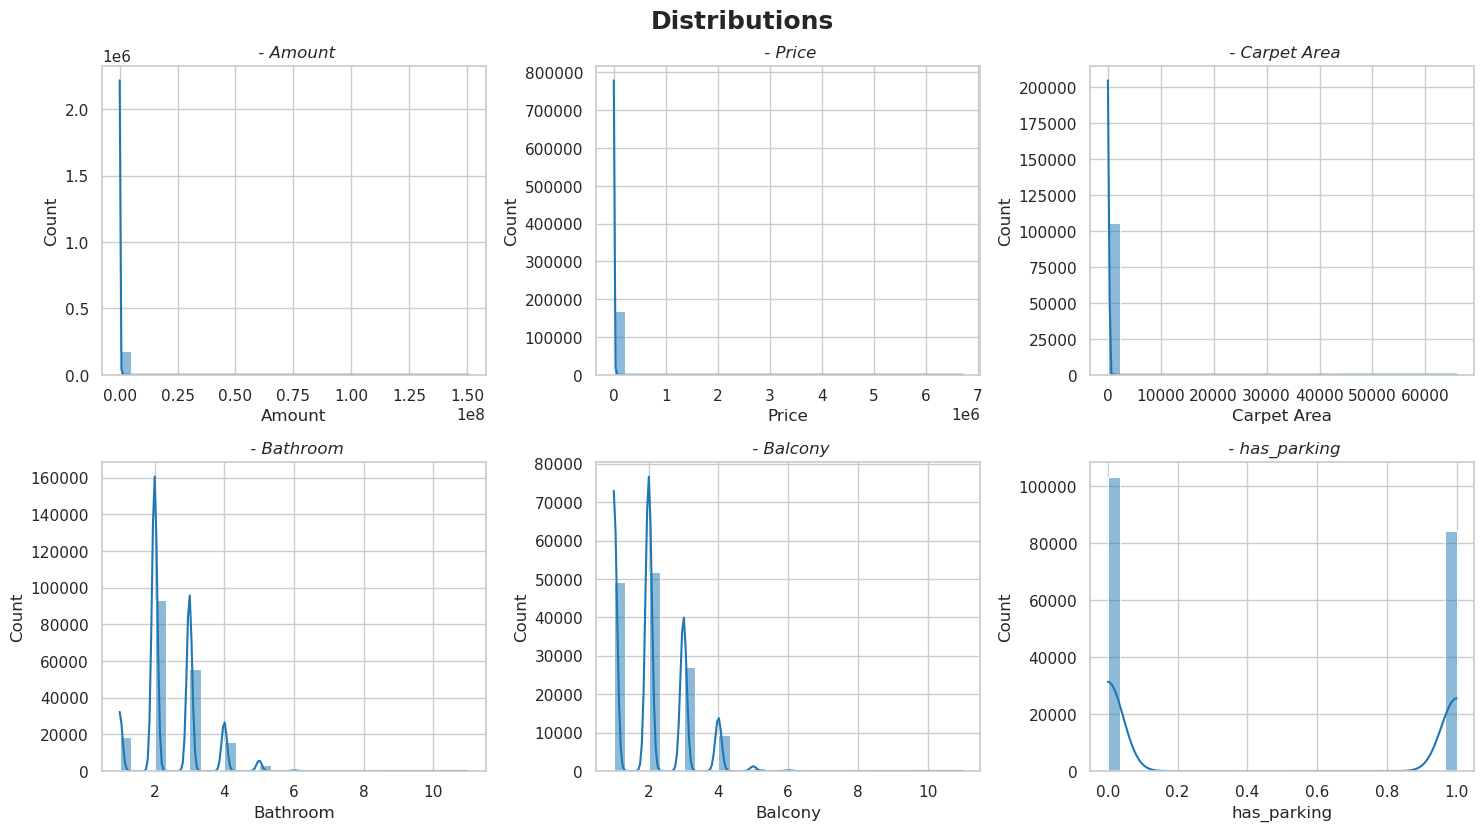

In [23]:
def plot_histograms(df, num_cols, title=""):

    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15,12))
    plt.suptitle("Distributions", fontsize=18, fontweight = "bold")

    for i, col in enumerate(num_cols):
        row = i // 3
        col_id = i % 3
        ax = axes[row, col_id]
        sns.histplot(data=df, x=col, kde=True, ax=ax, bins=30)
        ax.set_title(f"{title} - {col}", fontsize=12, style="italic")        


    axes = axes.flatten()
    for j in range(len(num_cols), len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

plot_histograms(df, num_cols)

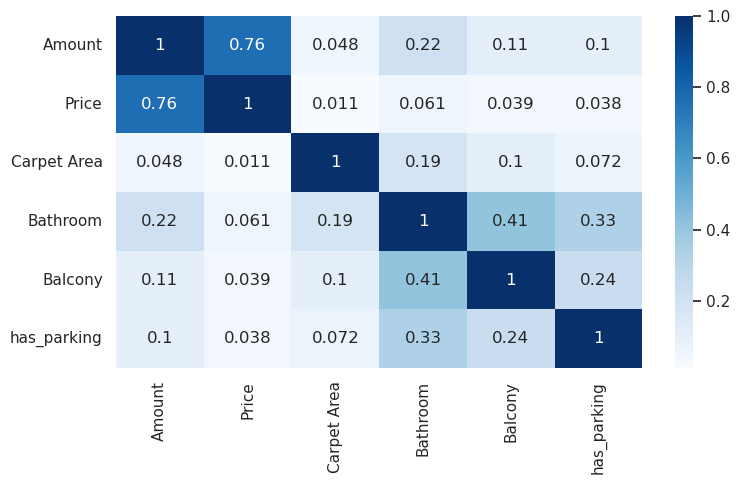

In [24]:
plt.figure(figsize=(8,5))
sns.heatmap(data=df.corr(numeric_only=True), annot=True, cmap="Blues")
plt.tight_layout()
plt.show()

                                                    FINDING OUTLIER

In [25]:
def find_outlier_iqr(df, num_cols, threshold=1.5):
    outlier_summary = {}

    for i, col in enumerate(num_cols):
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - threshold * IQR
        upper_bound = Q3 + threshold * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

        outlier_summary[col] = {
            "Outlier Count" : outliers.shape[0],
            "Outliner Percentange" : f"%{(outliers.shape[0] / df.shape[0]) * 100:.2f}",
            "lower Bound" : f"{lower_bound:.2f}",
            "Upper Bound" : f"{upper_bound:.2f}"
        }

    return pd.DataFrame(outlier_summary)

In [26]:
find_outlier_iqr(df, small_cols)

,Bathroom,Balcony,has_parking
Outlier Count,3661,64,0
Outliner Percentange,%1.95,%0.03,%0.00
lower Bound,0.50,-2.00,-1.50
Upper Bound,4.50,6.00,2.50


In [27]:
find_outlier_iqr(df, big_cols)

,Amount,Price,Carpet Area
Outlier Count,12283,7932,4921
Outliner Percentange,%6.55,%4.23,%2.62
lower Bound,-103763.44,-3432.50,-23.23
Upper Bound,311720.43,17179.50,236.90


In [28]:
def remove_outlier_from_column(df, target_cols, threshold=1.5):
    df_clean = df[target_cols].copy()

    Q1 = df_clean[target_cols].quantile(0.25)
    Q3 = df_clean[target_cols].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - threshold * IQR
    upper_bound = Q3 + threshold * IQR

    df_clean = df_clean[(df_clean[target_cols] >= lower_bound) & (df_clean[target_cols] <= upper_bound)]

    return df_clean.copy()

In [29]:
df_small = remove_outlier_from_column(df, small_cols, threshold=2)

In [30]:
df_big = remove_outlier_from_column(df, big_cols, threshold=1)

In [31]:
df_num = df_small.join(df_big)

In [32]:
missing_data(df_num)

,features,percentage_of_missing_data
0,Bathroom,%0.61
1,Balcony,%26.12
2,has_parking,%0.00
3,Amount,%14.52
4,Price,%14.91
5,Carpet Area,%48.41


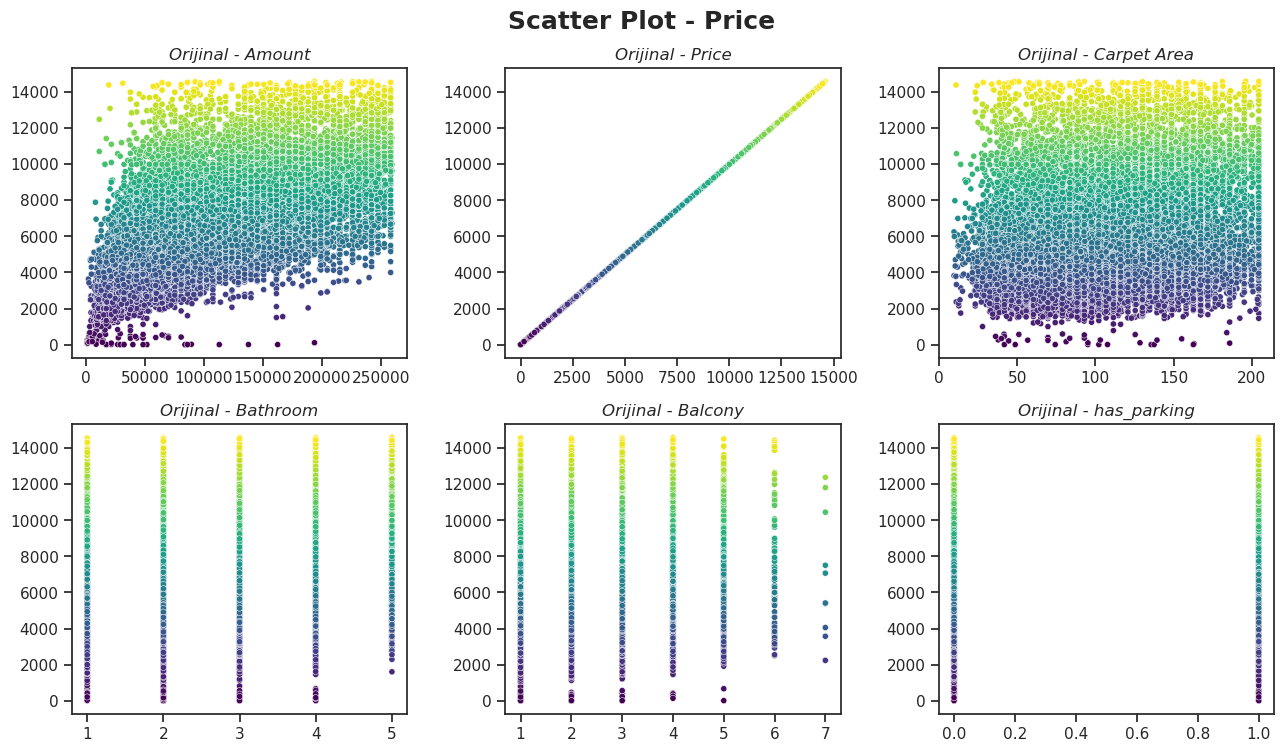

In [33]:
scatter_plot(df_num, num_cols)

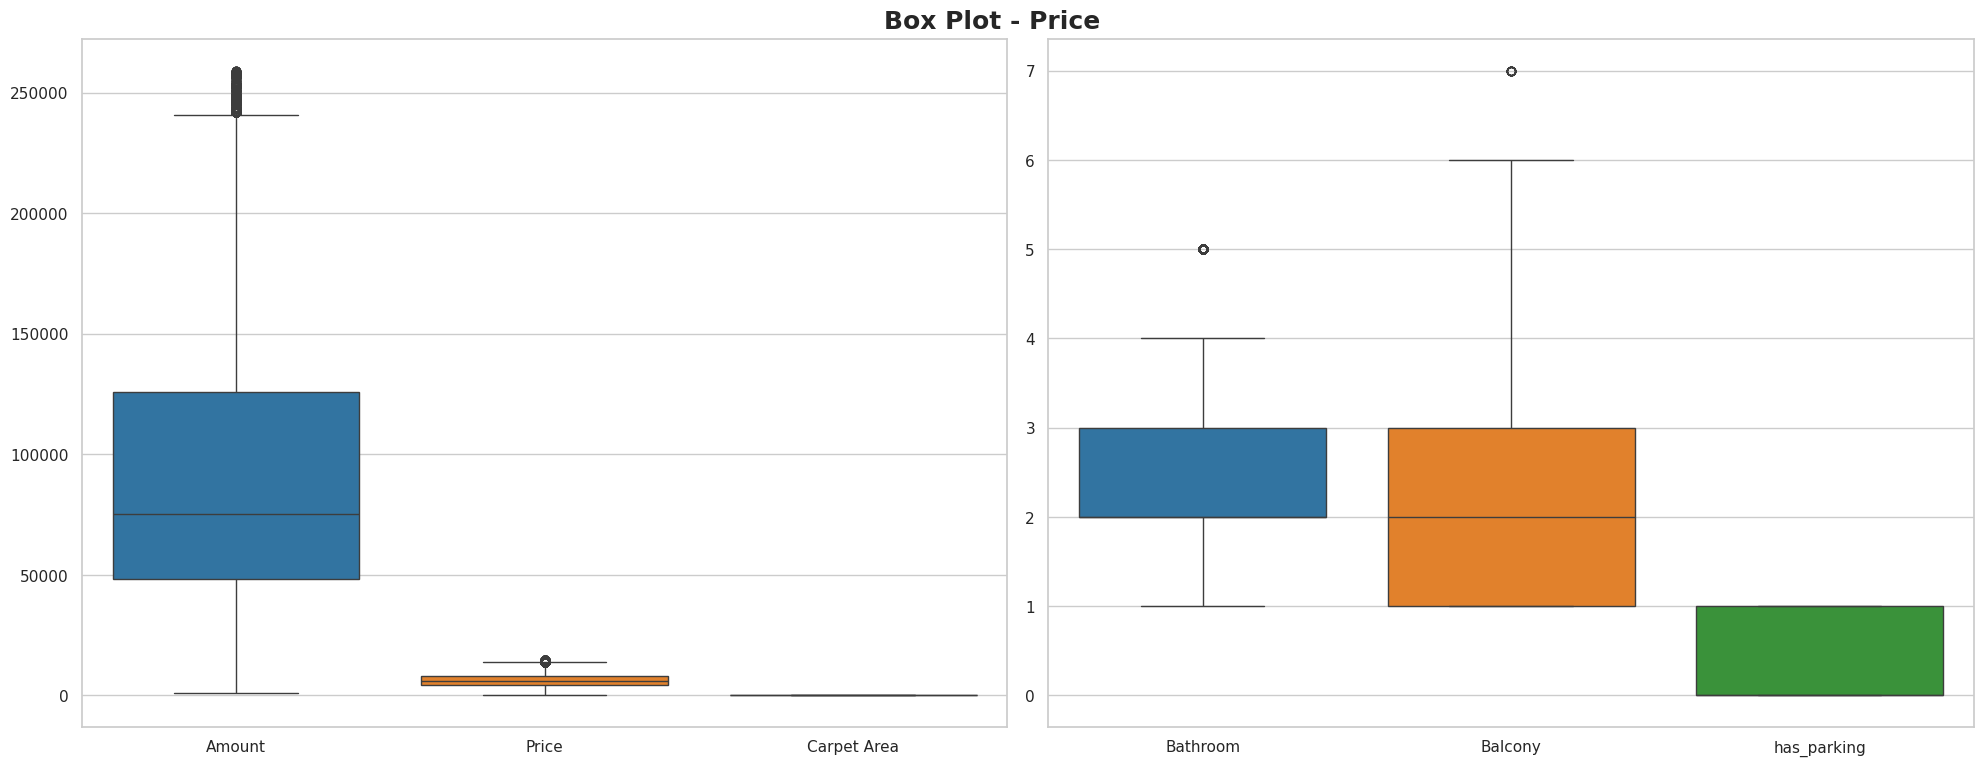

In [34]:
box_plot(df_num, num_cols) 

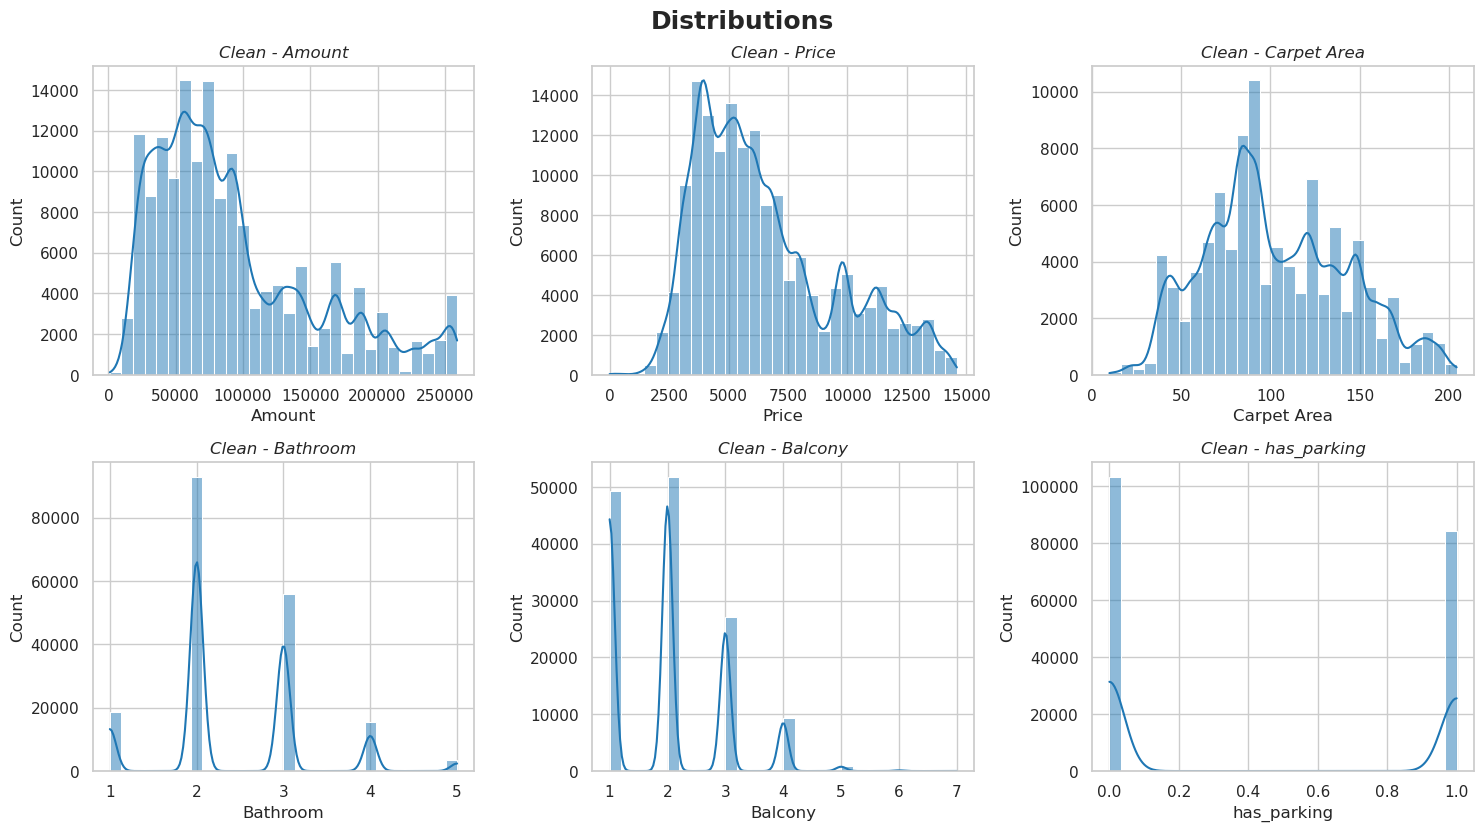

In [35]:
plot_histograms(df_num, num_cols, "Clean")

In [36]:
df[df["Floor"].str.contains("Ground", na=False)]["Floor"].unique()

array(['Ground out of 7', 'Ground out of 2', 'Ground out of 3',
       'Ground out of 4', 'Ground out of 5', 'Ground out of 1',
       'Ground out of 6', 'Ground out of 28', 'Ground out of 8',
       'Ground out of 14', 'Ground out of 12', 'Ground out of 10',
       'Ground out of 13', 'Ground', 'Ground out of 11',
       'Ground out of 9', 'Ground out of 20', 'Ground out of 15',
       'Ground out of 21', 'Ground out of 19', 'Ground out of 18',
       'Ground out of 40', 'Ground out of 32', 'Ground out of 16',
       'Ground out of 17', 'Ground out of 30', 'Ground out of 24',
       'Ground out of 27', 'Ground out of 31', 'Ground out of 33',
       'Ground out of 25', 'Ground out of 26', 'Ground out of 22',
       'Ground out of 35', 'Ground out of 23', 'Ground out of 29'],
      dtype=object)

In [37]:
df[df["Floor"].str.contains("Lower Basement", na=False)]["Floor"].unique()

array(['Lower Basement out of 7', 'Lower Basement out of 6',
       'Lower Basement out of 12', 'Lower Basement out of 8',
       'Lower Basement out of 14', 'Lower Basement out of 3',
       'Lower Basement out of 13', 'Lower Basement out of 5',
       'Lower Basement out of 11', 'Lower Basement out of 4',
       'Lower Basement out of 1', 'Lower Basement out of 2',
       'Lower Basement out of 29', 'Lower Basement out of 10',
       'Lower Basement out of 9', 'Lower Basement out of 16',
       'Lower Basement out of 20', 'Lower Basement out of 50',
       'Lower Basement out of 23', 'Lower Basement out of 18',
       'Lower Basement out of 15', 'Lower Basement'], dtype=object)

In [38]:
df["location"].unique()

array(['thane', 'navi-mumbai', 'nagpur', 'mumbai', 'ahmedabad',
       'bangalore', 'chennai', 'gurgaon', 'hyderabad', 'indore', 'jaipur',
       'kolkata', 'lucknow', 'new-delhi', 'noida', 'pune', 'agra',
       'ahmadnagar', 'allahabad', 'aurangabad', 'badlapur', 'belgaum',
       'bhiwadi', 'bhiwandi', 'bhopal', 'bhubaneswar', 'chandigarh',
       'coimbatore', 'dehradun', 'durgapur', 'ernakulam', 'faridabad',
       'ghaziabad', 'goa', 'greater-noida', 'guntur', 'guwahati',
       'gwalior', 'haridwar', 'jabalpur', 'jamshedpur', 'jodhpur',
       'kalyan', 'kanpur', 'kochi', 'kozhikode', 'ludhiana', 'madurai',
       'mangalore', 'mohali', 'mysore', 'nashik', 'navsari', 'nellore',
       'palakkad', 'palghar', 'panchkula', 'patna', 'pondicherry',
       'raipur', 'rajahmundry', 'ranchi', 'satara', 'shimla', 'siliguri',
       'solapur', 'sonipat', 'surat', 'thrissur', 'tirupati', 'trichy',
       'trivandrum', 'udaipur', 'udupi', 'vadodara', 'vapi', 'varanasi',
       'vijayawada',

In [39]:
df["Status"].unique()

array(['Ready to Move', nan], dtype=object)

In [40]:
df["Transaction"].unique()

array(['Resale', 'New Property', nan, 'Other', 'Rent/Lease'], dtype=object)

In [41]:
df["Furnishing"].unique()

array(['Unfurnished', 'Semi-Furnished', 'Furnished', nan], dtype=object)

In [42]:
df["facing"].unique()

array([nan, 'East', 'West', 'North - East', 'North', 'North - West',
       'South', 'South -West', 'South - East'], dtype=object)

In [43]:
df["overlooking"].unique()

array([nan, 'Garden/Park', 'Garden/Park, Main Road', 'Main Road',
       'Pool, Garden/Park, Main Road', 'Garden/Park, Pool, Main Road',
       'Garden/Park, Pool', 'Main Road, Garden/Park',
       'Main Road, Garden/Park, Pool', 'Pool, Garden/Park', 'Pool',
       'Garden/Park, Main Road, Pool', 'Pool, Main Road',
       'Main Road, Pool, Garden/Park', 'Pool, Main Road, Garden/Park',
       'Main Road, Not Available', 'Main Road, Pool',
       'Garden/Park, Pool, Main Road, Not Available',
       'Garden/Park, Not Available', 'Pool, Main Road, Not Available'],
      dtype=object)

In [44]:
df["Ownership"].unique()

array([nan, 'Freehold', 'Co-operative Society', 'Power Of Attorney',
       'Leasehold'], dtype=object)

In [45]:
def convert_floor(x):
    if pd.isna(x):
        return None

    x = str(x).lower().strip()

    if "ground" in x:
        return 0
    elif "lower basement"  in x:
        return -1
    elif "upper basement" in x:
        return -0.5

    if "out of" in x:
        parts = x.split(" out of ")
        current_floor = int(parts[0].strip())
        total_floor = int (parts[1].strip())

        floor_ratio = current_floor / total_floor

        if floor_ratio == 0:
            return 0
        elif floor_ratio == 1:
            return 2
        elif floor_ratio > 0 and floor_ratio < 1:
            return 1
        else:
            try:
                return int(x)
            except:
                return None

df["Floor"] = df["Floor"].apply(convert_floor)

In [46]:
df["Floor"] = df["Floor"].fillna(df["Floor"].median())

In [47]:
num_cols1 = ["Amount", "Price", "Carpet Area", "Bathroom", "Balcony"]

for col in num_cols1:
    df_num[col] = df_num[col].fillna(df_num[col].median())

In [48]:
cat_cols = ["location", "Status", "Transaction", "Furnishing", "facing", "overlooking", "Ownership"]

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [49]:
df["Furnishing"] = df["Furnishing"].map({"Unfurnished": 0, "Semi-Furnished": 1, "Furnished": 2})

In [50]:
df_cat = df.select_dtypes("object")
df_cat = df_cat.join(df["Floor"])
df_cat = df_cat.join(df["Furnishing"])
df_cat

,location,Status,Transaction,facing,overlooking,Ownership,Floor,Furnishing
0,thane,Ready to Move,Resale,East,Main Road,Freehold,1.0,0
1,thane,Ready to Move,Resale,East,Garden/Park,Freehold,1.0,1
2,thane,Ready to Move,Resale,East,Garden/Park,Freehold,1.0,0
3,thane,Ready to Move,Resale,East,Main Road,Freehold,1.0,0
4,thane,Ready to Move,Resale,West,"Garden/Park, Main Road",Co-operative Society,1.0,0
...,...,...,...,...,...,...,...,...
187526,zirakpur,Ready to Move,New Property,East,Garden/Park,Freehold,1.0,1
187527,zirakpur,Ready to Move,Resale,North - East,"Garden/Park, Main Road",Freehold,1.0,0
187528,zirakpur,Ready to Move,Resale,East,"Garden/Park, Main Road",Freehold,1.0,2
187529,zirakpur,Ready to Move,Resale,East,Main Road,Freehold,2.0,1


In [51]:
df_new = df_cat.join(df_num)
df_new.head()

,location,Status,Transaction,facing,overlooking,Ownership,Floor,Furnishing,Bathroom,Balcony,has_parking,Amount,Price,Carpet Area
0,thane,Ready to Move,Resale,East,Main Road,Freehold,1.0,0,1.0,2.0,0,45161.2903,6000.0,46.4515
1,thane,Ready to Move,Resale,East,Garden/Park,Freehold,1.0,1,2.0,2.0,1,105376.3441,13799.0,43.9431
2,thane,Ready to Move,Resale,East,Garden/Park,Freehold,1.0,0,2.0,2.0,1,150537.6344,5833.0,72.3714
3,thane,Ready to Move,Resale,East,Main Road,Freehold,1.0,0,1.0,1.0,0,26881.7204,5833.0,49.2386
4,thane,Ready to Move,Resale,West,"Garden/Park, Main Road",Co-operative Society,1.0,0,2.0,2.0,1,172043.0108,5833.0,58.9934


In [52]:
def missing_data(df):
    table = []
    for col in df.columns:
        table.append({
            col : f"%{(df[col].isnull().sum() / df.shape[0])*100:.2f}"
        })
    table1 = pd.DataFrame(table, columns=df.columns).stack().reset_index().drop("level_0", axis=1)
    table2 = table1.rename(columns={"level_1":"features", 0:"percentage_of_missing_data"})
    return table2

missing_data(df_new) 

,features,percentage_of_missing_data
0,location,%0.00
1,Status,%0.00
2,Transaction,%0.00
3,facing,%0.00
4,overlooking,%0.00
5,Ownership,%0.00
6,Floor,%0.00
7,Furnishing,%0.00
8,Bathroom,%0.00
9,Balcony,%0.00


In [53]:
df_new["Price"] = np.log1p(df_new["Price"])

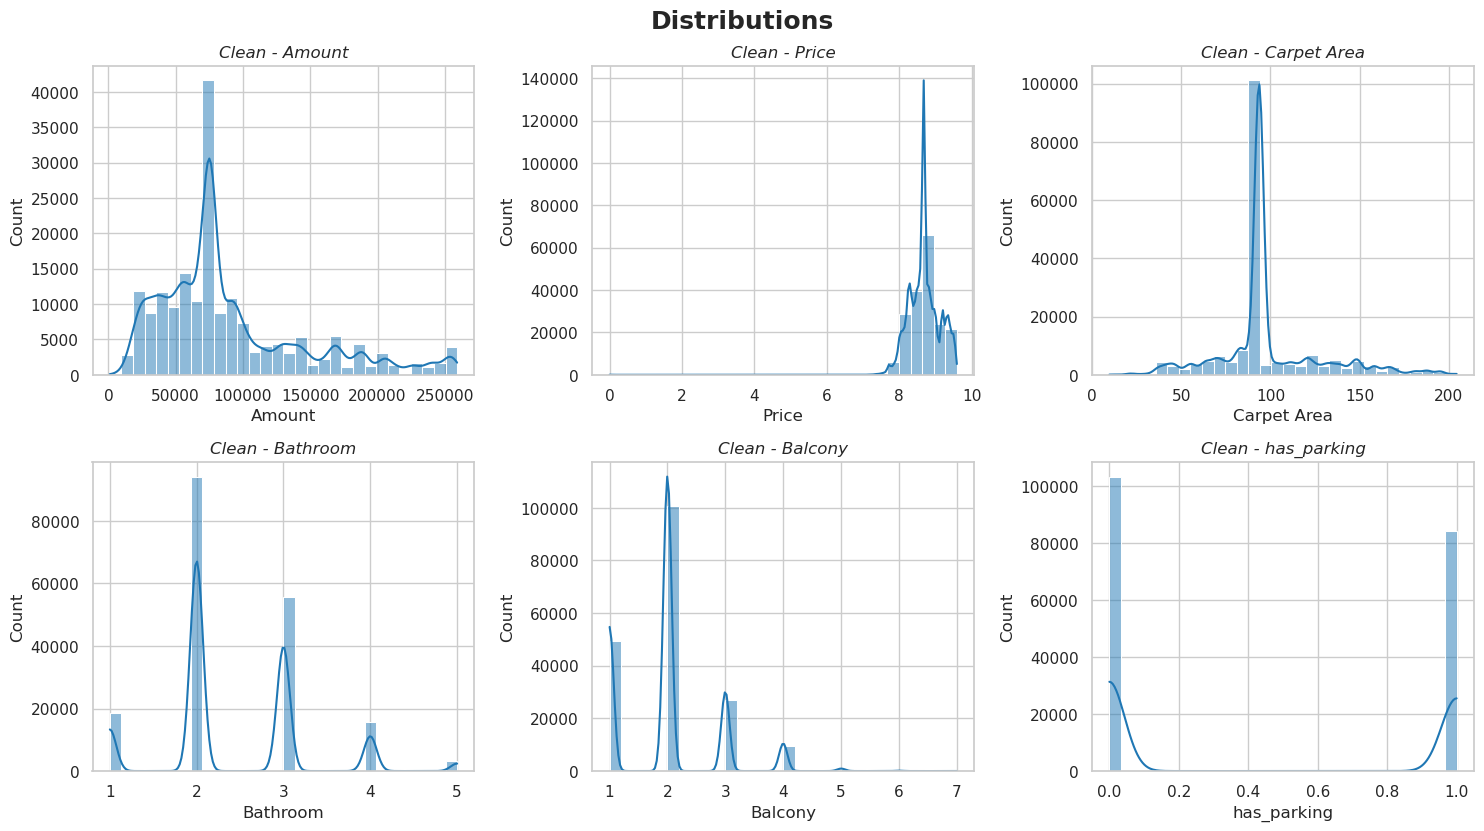

In [54]:
plot_histograms(df_new, num_cols, "Clean")

In [55]:
df_new.describe().style.background_gradient(cmap="Blues")

,Floor,Furnishing,Bathroom,Balcony,has_parking,Amount,Price,Carpet Area
count,187531.000000,187531.000000,187531.000000,187531.000000,187531.000000,187531.000000,187531.000000,187531.000000
mean,1.055431,0.701425,2.417830,1.999216,0.448854,90172.929114,8.683993,98.421950
std,0.439299,0.651503,0.845888,0.813293,0.497379,55872.593439,0.421252,28.865076
min,-1.000000,0.000000,1.000000,1.000000,0.000000,1075.268800,0.000000,9.661900
25%,1.000000,0.000000,2.000000,1.000000,0.000000,53763.440900,8.412388,92.903000
50%,1.000000,1.000000,2.000000,2.000000,0.000000,75268.817200,8.671458,93.646200
75%,1.000000,1.000000,3.000000,2.000000,1.000000,109677.419400,8.932873,97.548100
max,2.000000,2.000000,5.000000,7.000000,1.000000,259139.784900,9.588982,204.386600


In [56]:
X = df_new.drop("Price", axis=1)
y = df_new["Price"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

In [57]:
top_locations = X_train["location"].value_counts().nlargest(20).index
X_train["location"] = X_train["location"].apply(lambda x: x if x in top_locations else "other")
X_test["location"] = X_test["location"].apply(lambda x: x if x in top_locations else "other")

cat_cols = ["Status", "Transaction", "facing", "Ownership", "location", "overlooking"]

preprocessor = ColumnTransformer(
    [   
        ("onehot", OneHotEncoder(sparse_output=False), cat_cols)
    ], remainder="passthrough"
)


pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("xgb", XGBRegressor())
])

pipeline.fit(X_train, y_train)
y_test_pred = pipeline.predict(X_test)
y_train_pred = pipeline.predict(X_train)

y_test_pred_actual = np.expm1(y_test_pred)
y_train_pred_actual = np.expm1(y_train_pred)

In [58]:
y_test_actual = np.expm1(y_test)
y_train_actual = np.expm1(y_train)

In [59]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2 = r2_score(true, predicted)

    return mae, rmse, r2

In [60]:
def model_score_table(y_test_pred_actual, y_train_pred_actual, name):
    table = []
    
    y_test_mae, y_test_rmse, y_test_r2 = evaluate_model(y_test_actual, y_test_pred_actual)
    y_train_mae, y_train_rmse, y_train_r2 = evaluate_model(y_train_actual, y_train_pred_actual)
    
    table.append({
        "Model"                  : name,
        "Mean Absolute Error"    : y_test_mae,
        "Root Mean Square Error" : y_test_rmse,
        "R2 Score"               : y_test_r2,
        "Overfitting"            : y_train_r2 - y_test_r2,
        "Ratio"                  : y_test_rmse / y_train_rmse 
    })
    
    return pd.DataFrame(table).set_index("Model")  

In [61]:
model_score_table(y_test_pred_actual, y_train_pred_actual, name="XGB") 

,Mean Absolute Error,Root Mean Square Error,R2 Score,Overfitting,Ratio
Model,,,,,
XGB,386.13592,844.5519,0.903444,0.01792,1.104615


In [62]:
import joblib

with open ("house_price_model.pkl", "wb") as f:
    joblib.dump(pipeline, f)

In [63]:
pd.DataFrame(X_test).to_csv("house_test_data.csv", index=False)